Import and set up data

In [1]:
import seaborn as sns
import pandas as pd

import matplotlib.pyplot as plt

df = pd.read_csv("../Data/transformed_study_data.csv")

Implement the initial visualization

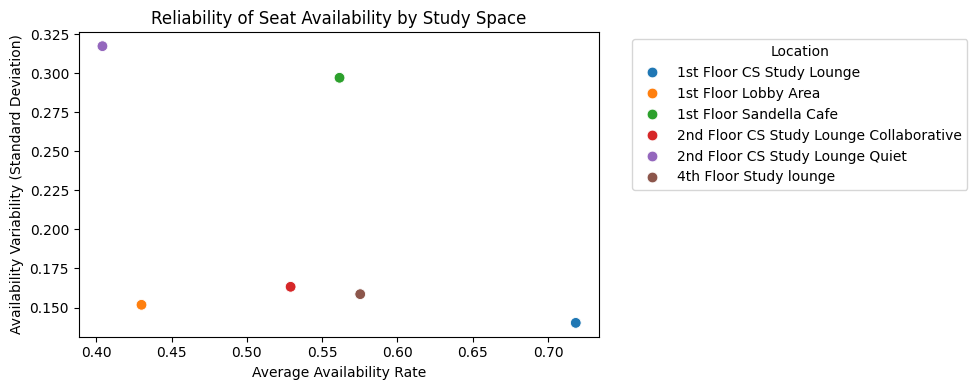

In [2]:
reliability_data = (
    df.groupby("location")["availability_rate"]
      .agg(["mean", "std"])
      .reset_index()
)

# reliability_data.columns = [
#     "location",
#     "avg_availability",
#     "availability_std"
# ]

reliability_data = (
    df.groupby("location")
      .agg(
          avg_availability=("availability_rate", "mean"),
          availability_std=("availability_rate", "std"),
          avg_occupancy=("occupancy_rate", "mean"),
          traffic_level=("traffic_level", "first")
      )
      .reset_index()
)

reliability_data

plt.figure(figsize=(10, 4))

sns.scatterplot(
    data=reliability_data,
    x="avg_availability",
    y="availability_std",
    hue="location",
    s=60
)

plt.title("Reliability of Seat Availability by Study Space")
plt.xlabel("Average Availability Rate")
plt.ylabel("Availability Variability (Standard Deviation)")

plt.legend(
    title="Location",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

Install additional packages

In [ ]:
!pip install plotly
!pip install nbformat

In [16]:
import plotly.express as px

fig = px.scatter(
    reliability_data,
    x="avg_availability",
    y="availability_std",
    color="location",
    custom_data=[
        "location",
        "avg_occupancy",
        "traffic_level"
    ]
)

fig.update_traces(
    hovertemplate=
    "<b>%{customdata[0]}</b><br><br>"
    "Average Availability: %{x:.1%}<br>"
    "Availability Variability: %{y:.1%}<br>"
    "Average Occupancy: %{customdata[1]:.1%}<br>"
    "Traffic Level: %{customdata[2]}"
    "<extra></extra>"
)

fig.update_layout(
    title="Reliability of Seat Availability by Study Space",
    xaxis_title="Average Availability Rate",
    yaxis_title="Availability Variability (Standard Deviation)",
    legend_title_text="Location"
)

fig.update_xaxes(tickformat=".0%")
fig.update_yaxes(tickformat=".0%")

fig.show()